<a href="https://colab.research.google.com/github/hiba-ai-ing/projet-mL/blob/main/TP2_ML_Sabir_Hiba.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Partie I : Questions de réflexion**

**Question1**

les trois principales métriques utilisées pour évaluer les prédictions d’un modèle de régression:
**MAE:**

 -mesure la moyenne des écarts absolus entre les valeurs réelles et prédites.

 Plus la MAE est faible, meilleures sont
les prédictions.


**RMSE:**
-racine carrée de la moyenne des erreurs au carré.

-Toujours RMSE ≥MAE (Elle pénalise davantage les grandes
erreurs que la MAE.)


**R2:**

-mesure la qualité du modèle relativement à un modèle de référence qui prédirait toujours la moyenne de Y

-plus il est proche de 1 , meilleures sont les prédictions


**Question 2)**
lintercept b0 est la valeur predite lorsque touts kles variables (les features) sont à 0

- la significatuon de b1: combien s'augmente Y lorsque x1 augmente d'une unité et les autres features sont constantes

**Question 3)**
 La multicolinéarité peut rendre les coefficients du modèle instables et leur interprétation plus difficile. Elle peut être
diagnostiquée notamment à l’aide des corrélations entre prédicteurs et du VIF (Variance Inflation Factor)
plus le VIF de Xjest eleve,  

plus Xj contient une information deja presente dans les autres predicteurs et plus
l'estimation de son coefficient peut devenir instable.
**Question 4)**
la métrique est VIF qui évalue si les coefficients estimés d’un modèle de régression linéaire
multiple sont fiables, en mesurant le niveau de multicolinéarité entre les variables explicatives



**Question 5)**
En dehors du problème de multicolinéarité, quatre principales hypothèses doivent être examinées afin de déterminer si un modèle de régression linéaire est adapté aux données :

1) Linéarité :
La relation entre la variable cible (Y) et chaque variable explicative (X) doit être approximativement linéaire. Autrement dit, une variation d’une variable explicative doit avoir un effet qui peut être correctement représenté par une relation linéaire avec (Y). Cette hypothèse peut notamment être vérifiée à l’aide de graphiques représentant les valeurs observées et les valeurs prédites ou à partir des résidus.

2) Indépendance des erreurs :
Les erreurs de prédiction (résidus) d’une observation doivent être indépendantes de celles des autres observations. Il ne doit donc pas exister de dépendance systématique entre les erreurs. Cette hypothèse est particulièrement importante lorsque les données sont ordonnées dans le temps, car les erreurs successives peuvent être corrélées.

3) Homoscédasticité :
La dispersion des résidus (e_i = y_i - \hat{y}_i) autour de zéro doit rester approximativement constante quelle que soit la valeur prédite (\hat{y}_i). Autrement dit, l’amplitude des erreurs ne doit pas augmenter ou diminuer systématiquement lorsque les valeurs prédites augmentent. Une dispersion qui forme par exemple un entonnoir peut indiquer une hétéroscédasticité.

4) Normalité des résidus :
Les résidus sont supposés suivre approximativement une distribution normale centrée autour de zéro. Cette hypothèse signifie que les petites erreurs positives et négatives sont les plus fréquentes et que les erreurs très importantes sont moins fréquentes. Elle peut notamment être vérifiée à l’aide d’un histogramme des résidus ou d’un graphique Q-Q.
**Question 6)**
Dans une régression linéaire avec intercept, cela crée une
dépendance linéaire parfaite entre les variables encodées.
L’option drop="first" permet donc de conserver seulement k-1 colonnes


**Partie II : Construction et évaluation d’un modèle de régression linéaire multiple**



In [38]:
# Bibliothèques générales
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Partitionnement des données
from sklearn.model_selection import train_test_split


# Encodage des variables catégorielles
from sklearn.preprocessing import OneHotEncoder

# Modele de régression linéaire
from sklearn. linear_model import LinearRegression

# Metriques d'évaluation
from sklearn.metrics import ( mean_absolute_error, root_mean_squared_error, r2_score)

# Calcul du VIF
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools. tools import add_constant

# Seed
SEED = 42
np.random. seed(SEED)

# Chargement du dataset
url = "https://raw.githubusercontent.com/pujarisurakshashankar/car-market-trend-analysis/main/data/CarDekho_Dataset.csv"
df = pd.read_csv(url)
df













,Car_Name,Year,Selling_Price,Present_Price,Kms_Driven,Fuel_Type,Seller_Type,Transmission,Owner
0,ritz,2014,3.35,5.59,27000,Petrol,Dealer,Manual,0
1,sx4,2013,4.75,9.54,43000,Diesel,Dealer,Manual,0
2,ciaz,2017,7.25,9.85,6900,Petrol,Dealer,Manual,0
3,wagon r,2011,2.85,4.15,5200,Petrol,Dealer,Manual,0
4,swift,2014,4.60,6.87,42450,Diesel,Dealer,Manual,0
...,...,...,...,...,...,...,...,...,...
296,city,2016,9.50,11.60,33988,Diesel,Dealer,Manual,0
297,brio,2015,4.00,5.90,60000,Petrol,Dealer,Manual,0
298,city,2009,3.35,11.00,87934,Petrol,Dealer,Manual,0
299,city,2017,11.50,12.50,9000,Diesel,Dealer,Manual,0


Cette première étape consiste à importer les bibliothèques nécessaires à la réalisation de l’analyse et à la construction du modèle de régression linéaire. Les bibliothèques NumPy et Pandas sont utilisées respectivement pour les calculs numériques et la manipulation des données, tandis que Matplotlib permet leur visualisation. La fonction train_test_split sera utilisée ultérieurement pour partitionner les données en ensembles d’apprentissage et de test. L’encodage des variables catégorielles sera réalisé à l’aide de OneHotEncoder. Les métriques MAE, RMSE et R² permettront d’évaluer les performances du modèle, tandis que le VIF sera utilisé pour examiner la présence éventuelle de multicolinéarité entre les variables explicatives.

Une graine aléatoire (SEED = 42) est également fixée afin de garantir la reproductibilité des résultats. Enfin, le jeu de données CarDekho est chargé à partir d’un fichier CSV distant à l’aide de Pandas et stocké dans un DataFrame nommé df. Cette étape permet ainsi de disposer des données nécessaires pour les différentes étapes de préparation, d’analyse et de modélisation.

In [39]:
#Q2. Sélection des variables :
#séparer la variable cible X et la cible Y :
x=df[[
"Present_Price" ,"Year", "Kms_Driven" ,"Fuel_Type" , "Transmission" , "Seller_Type"]]
y=df["Selling_Price"]



Dans cette étape, les données sont séparées en variables explicatives (X) et en variable cible (Y). Les variables (X) sont Present_Price, Year, Kms_Driven, Fuel_Type, Transmission et Seller_Type, tandis que Selling_Price constitue la variable cible à prédire. Les variables catégorielles seront ensuite encodées en variables numériques.


In [47]:
#Q3. Partitionnement des données :
x_train,x_temp,y_train,y_temp=train_test_split(x,y,test_size=0.3,random_state=SEED)
#il ne faut pas utiliser stratify puisque e n'est pas une variable catégorielle  , y est continue .
#diviser les 30% restants en validation et test :
x_val,x_test,y_val,y_test=train_test_split(x_temp,y_temp,test_size=0.5,random_state=SEED)


#afficher les dimensions de  X_train, X_val et X_test.
print("Dimensions de x_train:", x_train.shape)
print("Dimensions de x_val:", x_val.shape)
print("Dimensions de x_test:", x_test.shape)


Dimensions de x_train: (210, 6)
Dimensions de x_val: (45, 6)
Dimensions de x_test: (46, 6)


Les données sont réparties en trois ensembles : **70 % pour l’apprentissage, 15 % pour la validation et 15 % pour le test**. La variable cible étant continue, la stratification (`stratify`) n’est pas utilisée. La séparation permet d’entraîner le modèle sur les données d’apprentissage, de l’ajuster grâce à l’ensemble de validation et d’évaluer ses performances finales sur l’ensemble de test.


In [49]:
#Q4. Encodage des variables catégorielles :
#afficher les types des variables:
x.dtypes
#les variables catégorielles sont :Fuel_Type,Transmission, Seller_Type
colonne_catégorielle=["Fuel_Type","Transmission", "Seller_Type"]
#création de l'encodeur
encodeur=OneHotEncoder( drop="first",handle_unknown="ignore",sparse_output=False).set_output(transform="pandas")
#ajuster l'encodeur sur les données d'entraînement
x_train_cat=encodeur.fit_transform(x_train[colonne_catégorielle])
#transformer les données de validation et de test
x_val_cat=encodeur.transform(x_val[colonne_catégorielle])
x_test_cat=encodeur.transform(x_test[colonne_catégorielle])
#vérification des modalités apprises
print("Modalités colonne 1:",encodeur.categories_[0],
      "Modalités colonne 2:",encodeur.categories_[1],
      "Modalités colonne 3:",encodeur.categories_[2])
print("variables créées:",list(x_train_cat.columns))




Modalités colonne 1: ['CNG' 'Diesel' 'Petrol'] Modalités colonne 2: ['Automatic' 'Manual'] Modalités colonne 3: ['Dealer' 'Individual']
variables créées: ['Fuel_Type_Diesel', 'Fuel_Type_Petrol', 'Transmission_Manual', 'Seller_Type_Individual']


Les variables catégorielles Fuel_Type, Transmission et Seller_Type sont transformées en variables numériques à l’aide de l’encodage One-Hot. L’option drop="first" permet d’éviter la redondance entre les modalités. L’encodeur est ajusté uniquement sur les données d’apprentissage, puis appliqué aux ensembles de validation et de test afin d’éviter toute fuite de données. L’option handle_unknown="ignore" permet également de gérer les modalités éventuellement absentes lors de l’apprentissage.

In [50]:
#suppression des anciennes variables
x_train = x_train.drop(columns=["Fuel_Type", "Transmission", "Seller_Type"])
x_val = x_val.drop(columns=["Fuel_Type", "Transmission", "Seller_Type"])
x_test = x_test.drop(columns=["Fuel_Type", "Transmission", "Seller_Type"])
#ajout des variables encodés
x_train=pd.concat([x_train,x_train_cat],axis=1)
x_val=pd.concat([x_val,x_val_cat],axis=1)
x_test=pd.concat([x_test,x_test_cat],axis=1)
#Afficher les noms des variables finales
x_train.columns
x_val.columns
x_test.columns
#les dimensions obtenues
print("train dimension:",x_train.shape)
print("validation dimension:",x_val.shape)
print("test dimension:",x_test.shape)


train dimension: (210, 7)
validation dimension: (45, 7)
test dimension: (46, 7)


,0
Present_Price,float64
Year,int64
Kms_Driven,int64
Fuel_Type_Diesel,float64
Fuel_Type_Petrol,float64
Transmission_Manual,float64
Seller_Type_Individual,float64


Après l’encodage, les anciennes variables catégorielles sont supprimées afin d’éviter leur duplication. Les nouvelles variables numériques issues du One-Hot Encoding sont ensuite ajoutées aux ensembles d’apprentissage, de validation et de test. Cette étape permet d’obtenir les variables finales qui seront utilisées pour entraîner et évaluer le modèle de régression linéaire.

aprés avoir galérer avec le drop qui ne fonctionne pas et ne supprime pas les colonnes subject, l'ereur etait que drop lui faut une affectation à la variable pour sauvegarder le nouveau x_train  

In [51]:
# Construire un modèle de régression linéaire multiple
regressor=LinearRegression()
#entrainer le modèle sur train
regressor.fit(x_train,y_train)
#l’intercept du modèle:
print("b0=",regressor.intercept_)
print("b1=",regressor.coef_[0])
print("b2=",regressor.coef_[1])
print("b3=",regressor.coef_[2])
print("b4=",regressor.coef_[3])
print("b5=",regressor.coef_[4])
print("b6=",regressor.coef_[5])
print("b7=",regressor.coef_[6])
x_train.dtypes
#le coefficient associé à chacune des variables explicatives.

b0= -746.5083607784704
b1= 0.4140806334807082
b2= 0.3718416533374085
b3= -4.485928607522727e-06
b4= 2.7109067671778893
b5= 0.6778701886685936
b6= -1.3734456914684074
b7= -1.2192380586683673


,0
Present_Price,float64
Year,int64
Kms_Driven,int64
Fuel_Type_Diesel,float64
Fuel_Type_Petrol,float64
Transmission_Manual,float64
Seller_Type_Individual,float64


les coefficients associés à year et km_driven sont positive est plus proches entre eux , ainsi que b6 et b7 de transmission_manual et seller_type_individual sont presque egale et négative coefficient
provenant d’une variable catégorielle encodée. par contre Fuel_Type_Diesel et Fuel_Type_fuel sont différents et positives

In [57]:
#Question 6
y_train_pred=regressor.predict(x_train)
y_val_pred=regressor.predict(x_val)
y_test_pred=regressor.predict(x_test)
#metrique sur entrainement
mae_train=mean_absolute_error(y_train,y_train_pred)
rmse_train=root_mean_squared_error(y_train,y_train_pred)
r2_train=r2_score(y_train,y_train_pred)
######affichage
print("MAE train:",mae_train)
print("RMSE train:",rmse_train)
print("R2 train:",r2_train)
#metrique sur validation
mae_val=mean_absolute_error(y_val,y_val_pred)
rmse_train=root_mean_squared_error(y_val,y_val_pred)
r2_val=r2_score(y_val,y_val_pred)
####affichage
print("MAE val:",mae_val)
print("RMSE val:",rmse_train)
print("R2 val:",r2_val)
#metrique sur test
mae_test=mean_absolute_error(y_test,y_test_pred)
rmse_test=root_mean_squared_error(y_test,y_test_pred)
r2_test=r2_score(y_test,y_test_pred)
#######affichage
print("MAE test:",mae_test)
print("RMSE test:",rmse_test)
print("R2 test:",r2_test)






MAE train: 1.140954329022953
RMSE train: 1.718908755774701
R2 train: 0.8796116566761706
MAE val: 1.1541562411493842
RMSE val: 1.7914640578742502
R2 val: 0.8812624443819119
MAE test: 1.3170565430044605
RMSE test: 1.907645467060466
R2 test: 0.8780659179747162


Les performances du modèle de régression linéaire multiple ont été évaluées sur les ensembles d’entraînement, de validation et de test à l’aide des métriques MAE, RMSE et R².

Sur l’ensemble de test, le modèle obtient un MAE de 1,317 et un RMSE de 1,908. Le coefficient de détermination R² atteint 0,878, ce qui signifie que le modèle explique environ 87,8 % de la variabilité de la variable cible « Selling_Price ».

Les résultats obtenus sur les trois ensembles sont relativement proches. En particulier, les valeurs de R² sont de 0,880 pour l’entraînement, 0,881 pour la validation et 0,878 pour le test. Cette proximité indique que le modèle généralise correctement sur des données qu’il n’a pas utilisées lors de son entraînement et ne présente pas de signe important de surapprentissage.

R² train = 0,880
R² validation = 0,881
R² test = 0,878

Les trois valeurs sont très proches.

➡️ Conclusion : le modèle présente une bonne généralisation.

Il n'y a pas de surapprentissage, car le R² sur train n'est pas nettement supérieur à celui de validation/test.

Il n'y a pas non plus de sous-apprentissage, car le R² est élevé (environ 0,88), indiquant que le modèle explique une grande partie de la variabilité de la cible.



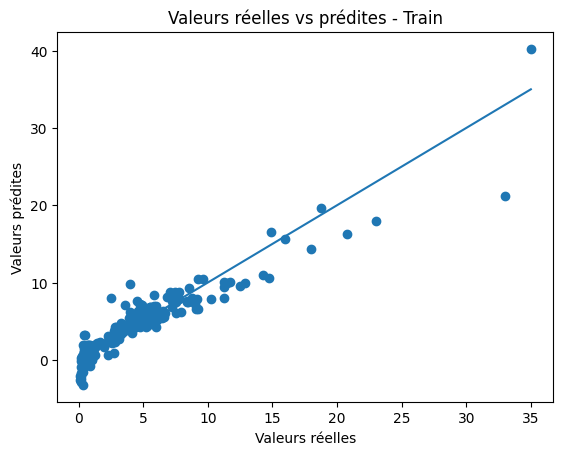

In [58]:
# Graphique Train
plt.scatter(y_train, y_train_pred)
plt.xlabel("Valeurs réelles")
plt.ylabel("Valeurs prédites")
plt.title("Valeurs réelles vs prédites - Train")

# diagonale idéale
plt.plot([y_train.min(), y_train.max()],
         [y_train.min(), y_train.max()])

plt.show()

Pour l’ensemble Train, on observe une forte concentration des points dans la première partie du graphique, correspondant aux faibles valeurs de `Selling_Price`. Quelques points, sont davantage dispersés pour des valeurs plus élevées. La majorité des observations reste cependant proche de la diagonale, qui représente le cas idéal où la valeur prédite est égale à la valeur réelle. Les points au-dessus de la diagonale correspondent à une surestimation, tandis que les points en dessous correspondent à une sous-estimation.

Cette observation est cohérente avec les résultats obtenus précédemment : le modèle présente un **R² de 0,880**, ce qui indique qu'il explique une grande partie de la variabilité de `Selling_Price`. Le **MAE de 1,141** et le **RMSE de 1,719** montrent que les erreurs de prédiction restent globalement limitées, même si quelques observations plus éloignées de la diagonale entraînent des erreurs plus importantes. Ainsi, le graphique confirme globalement les bonnes performances du modèle sur l'ensemble Train.


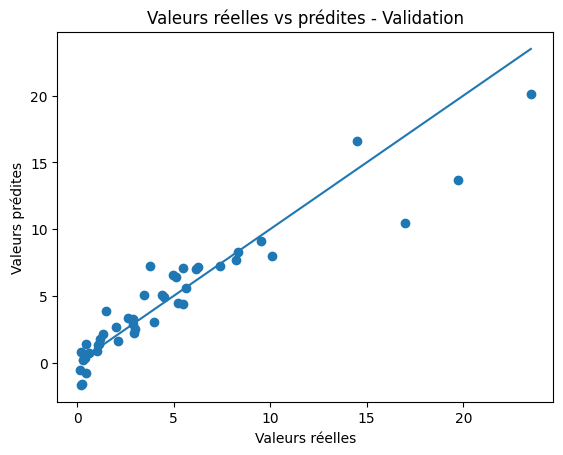

In [59]:
plt.scatter(y_val, y_val_pred)
plt.xlabel("Valeurs réelles")
plt.ylabel("Valeurs prédites")
plt.title("Valeurs réelles vs prédites - Validation")

plt.plot([y_val.min(), y_val.max()],
         [y_val.min(), y_val.max()])

plt.show()

Ensemble Validation

Pour l’ensemble Validation, on observe moins de points que pour l’ensemble Train, ce qui est normal puisque cet ensemble représente 15 % des données. Les points sont principalement concentrés dans la première partie du graphique, correspondant aux faibles valeurs de Selling_Price. Quelques observations sont plus dispersées pour des valeurs plus élevées. Globalement, les points restent assez proches de la diagonale représentant le cas idéal. Les points au-dessus de la diagonale indiquent une surestimation, tandis que ceux en dessous indiquent une sous-estimation.

Ces observations sont cohérentes avec les métriques obtenues : MAE = 1,154, RMSE = 1,791 et R² = 0,881. Les performances sont très proches de celles obtenues sur Train, ce qui indique que le modèle conserve une bonne capacité de généralisation sur l’ensemble Validation.

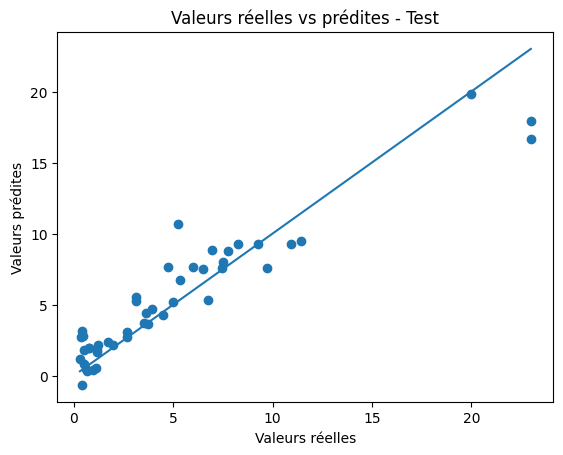

In [60]:
plt.scatter(y_test, y_test_pred)
plt.xlabel("Valeurs réelles")
plt.ylabel("Valeurs prédites")
plt.title("Valeurs réelles vs prédites - Test")

plt.plot([y_test.min(), y_test.max()],
         [y_test.min(), y_test.max()])

plt.show()

Ensemble Test

Pour l’ensemble Test, le nombre de points est également limité, puisque cet ensemble représente 15 % des données. Les observations sont principalement regroupées dans les faibles valeurs de Selling_Price, avec quelques points plus dispersés pour les valeurs élevées. La majorité des points se situe globalement autour de la diagonale idéale, même si certaines observations présentent des écarts plus importants.

Cette observation est cohérente avec les métriques obtenues sur Test : MAE = 1,317, RMSE = 1,908 et R² = 0,878. Le R² reste élevé et proche de ceux de Train et Validation, tandis que le MAE et le RMSE sont légèrement plus élevés, ce qui traduit quelques erreurs de prédiction plus importantes. Dans l'ensemble, les résultats graphiques confirment donc les bonnes performances du modèle et sa bonne généralisation sur les données de test.



In [61]:
#variance inflation factor — inflation due à la colinéarité
vif = pd.DataFrame()

vif["Variable"] = x_train.columns

vif["VIF"] = [
    variance_inflation_factor(x_train.values, i)
    for i in range(x_train.shape[1])
]

print(vif)

                 Variable        VIF
0           Present_Price   1.645334
1                    Year   1.395790
2              Kms_Driven   1.441728
3        Fuel_Type_Diesel  17.348979
4        Fuel_Type_Petrol  17.193169
5     Transmission_Manual   1.147365
6  Seller_Type_Individual   1.373276


Le facteur d'inflation de la variance (VIF) a été calculé pour chaque variable explicative à partir de l'ensemble d'apprentissage (Train).

Variable	VIF
Present_Price	1,645
Year	1,396
Kms_Driven	1,442
Fuel_Type_Diesel	17,349
Fuel_Type_Petrol	17,193
Transmission_Manual	1,147
Seller_Type_Individual	1,373

La plupart des variables présentent un VIF inférieur à 5, ce qui indique une faible multicolinéarité. En revanche, Fuel_Type_Diesel et Fuel_Type_Petrol présentent des VIF supérieurs à 10, avec respectivement 17,349 et 17,193. Ces deux variables présentent donc un problème important de multicolinéarité et leurs coefficients doivent être interprétés avec prudence.

Ainsi, les coefficients obtenus à la question 5 ne peuvent pas tous être considérés comme parfaitement fiables pour une interprétation individuelle. Les coefficients des variables présentant un faible VIF sont relativement stables, tandis que ceux associés aux variables Fuel_Type_Diesel et Fuel_Type_Petrol peuvent être plus sensibles à la multicolinéarité. Cependant, cette situation ne signifie pas nécessairement que les prédictions du modèle sont mauvaises.

Globalement, le modèle présente de bonnes performances. Le coefficient de détermination est de 0,880 sur Train, 0,881 sur Validation et 0,878 sur Test. La proximité de ces valeurs montre que les performances restent stables sur les différents ensembles et indique une bonne capacité de généralisation à de nouvelles données. Sur l'ensemble Test, le MAE est de 1,317 et le RMSE de 1,908, ce qui indique que les erreurs de prédiction restent globalement limitées.

En conclusion, le modèle de régression linéaire multiple présente une bonne qualité prédictive et une bonne capacité de généralisation, sans signe important de surapprentissage. Sa principale limite concerne la forte multicolinéarité observée pour les variables liées au type de carburant, qui réduit la fiabilité de l'interprétation individuelle de leurs coefficients. Une amélioration possible serait d'étudier plus précisément cette multicolinéarité et son origine avant d'utiliser les coefficients pour tirer des conclusions sur l'effet de chaque variable.